# 10. Synthetic Realism Evaluation

Direct, quantitative evaluation of CVAE-generated spectra against the real spectra
they are meant to imitate (set `CONFIG_NAME` below; run notebook 03 first so the
synthetic pool exists).

| Section | Analysis |
|---------|----------|
| A | Mean ± 1σ spectra — real vs synthetic, per class |
| B | Representative overlay plots (5 random spectra each) |
| C | PCA / t-SNE / UMAP coloured by source and class |
| D | Biologically relevant Raman peak comparison |
| E | Distributional distances: MMD + sliced Wasserstein |
| F | Classifier two-sample test (C2ST) — logistic regression |
| G | Nearest-neighbour memorisation check |
| H | Intra-class diversity (pairwise distance distributions) |

All analyses are computed by `src/evaluation/synthetic_realism.py` (`load_data` +
`run_all`); this notebook is a thin driver. Figures and the `synth_eval_metrics.{json,csv}`
results are written under the experiment's results directory.

## Section 1: Imports & Setup

In [2]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Image, display

# Add project root to path (before importing src)
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.notebooks.experiment_utils import setup_experiment

print('Imports OK')

Imports OK


## Section 2: Load Configuration

In [3]:
CONFIG_NAME = 'exp_105'   # any experiment whose CVAE synthetic pool exists (run nb 03 first)
config, output_dir = setup_experiment(CONFIG_NAME)

# Derive output paths from the experiment, so switching CONFIG_NAME never writes
# into another experiment's folder.
EXP_ROOT     = config['paths']['experiment_root']
FIGURES_DIR  = f'{EXP_ROOT}/figures/synth_eval'
METRICS_PATH = f'{EXP_ROOT}/synth_eval_metrics.json'
FOLD_IDX     = 0    # which fold's synthetic spectra to evaluate (0-4)
SEED         = 42

print(f'Experiment -> {CONFIG_NAME}')
print(f'Figures    -> {FIGURES_DIR}')
print(f'Metrics    -> {METRICS_PATH}')
print(f'Fold used  -> {FOLD_IDX}')


EXPERIMENT SETUP

Working directory: c:\Users\Iulian\Documents\glioma\glioma-synthetic-data

 Loaded configuration: exp_105
   Description: TSAR Regimen: Fingerprint crop (700-1800), patient cap (500), and dynamic Raman augmentation

 Output directory: C:\Users\Iulian\Documents\glioma\glioma-synthetic-data\results\results
  Experiment already registered (re-running)

--------------------------------------------------------------------------------
Configuration Summary:
--------------------------------------------------------------------------------
  Preprocessing:
    - AirPLS lambda: 100
    - Signal length: 1738
    - Crop region: [700, 1800]

  CV Strategy:
    - Split source: data/splits/strict_splits.json
    - Use group-aware CV: True
    - Hold out test set: True

  Models:
    - RF n_estimators: 100
    - SVM C: 1.0
    - CVAE epochs: 70


Figures   -> figures/synth_eval
Metrics   -> results/exp_105/synth_eval_metrics.json
Fold used -> 0


## Section 3: Preview Data

In [4]:
from src.evaluation.synthetic_realism import load_data

X_real, y_real, X_synth, y_synth, wavenumbers = load_data(
    config.to_dict(), fold_idx=FOLD_IDX, seed=SEED
)

print(f'Real spectra  : {X_real.shape}   classes: {dict(zip(*np.unique(y_real, return_counts=True)))}')
print(f'Synth spectra : {X_synth.shape}  classes: {dict(zip(*np.unique(y_synth, return_counts=True)))}')
print(f'Wavenumbers   : {len(wavenumbers)} points  ({wavenumbers[0]:.1f} - {wavenumbers[-1]:.1f} cm⁻¹)')

c:\Users\Iulian\Documents\glioma\glioma-synthetic-data\src\evaluation\synthetic_realism.py:48: UserWarning: umap-learn not installed — UMAP plot will be skipped. Install with: pip install umap-learn
  warnings.warn(


  Loading real spectra from glioma_dataset.h5 ...
Loading CV splits from: data/splits/strict_splits.json
Loading data from C:\Users\Iulian\Documents\glioma\glioma-synthetic-data\results\exp_102\data\glioma_dataset.h5...
[*] 'tumor_only=True': Filtering out healthy tissue...
    Filtered to 226284 Pure Tumor Spectra.
[OK] Spectral Crop: [700, 1800] cm-1 -> indices [337, 908]
  Wavenumber mapping: 699.91 -> 1799.14 cm-1
  Renormalizing to cropped region...
    After renormalization: min=0.000000, max=1.000000 (fingerprint region)
  Spectra shape after crop: (226284, 571)
  (No patient cap applied)
  Loading synthetic fold 0 from synthetic/ ...
Real spectra  : (226284, 571)   classes: {np.int64(0): np.int64(113766), np.int64(1): np.int64(112518)}
Synth spectra : (40000, 571)  classes: {np.int64(0): np.int64(20000), np.int64(1): np.int64(20000)}
Wavenumbers   : 571 points  (699.9 - 1799.1 cm⁻¹)


## Section 4: Run All Analyses

> **Expected runtime:** ~10–20 minutes (t-SNE dominates; UMAP is similar).  
> All figures are saved to disk as they complete.

In [5]:
from src.evaluation.synthetic_realism import run_all

results = run_all(
    config.to_dict(),
    figures_dir  = FIGURES_DIR,
    metrics_path = METRICS_PATH,
    fold_idx     = FOLD_IDX,
    seed         = SEED,
)


SYNTHETIC REALISM EVALUATION (exp_105)
Fold: 0  |  Figures -> figures\synth_eval  |  Metrics -> results/exp_105/synth_eval_metrics.json

Loading data ...
  Loading real spectra from glioma_dataset.h5 ...
Loading CV splits from: data/splits/strict_splits.json
Loading data from C:\Users\Iulian\Documents\glioma\glioma-synthetic-data\results\exp_102\data\glioma_dataset.h5...
[*] 'tumor_only=True': Filtering out healthy tissue...
    Filtered to 226284 Pure Tumor Spectra.
[OK] Spectral Crop: [700, 1800] cm-1 -> indices [337, 908]
  Wavenumber mapping: 699.91 -> 1799.14 cm-1
  Renormalizing to cropped region...
    After renormalization: min=0.000000, max=1.000000 (fingerprint region)
  Spectra shape after crop: (226284, 571)
  (No patient cap applied)
  Loading synthetic fold 0 from synthetic/ ...
  Real:  (226284, 571)  classes=[0 1]
  Synth: (40000, 571)  classes=[0 1]

[A] Mean +/- std spectra ...
  Saved: A_mean_std_spectra.pdf
  Saved: A_mean_std_spectra.png

[B] Representative overla

## Section 5: Display Figures


── A_mean_std_spectra.png ──


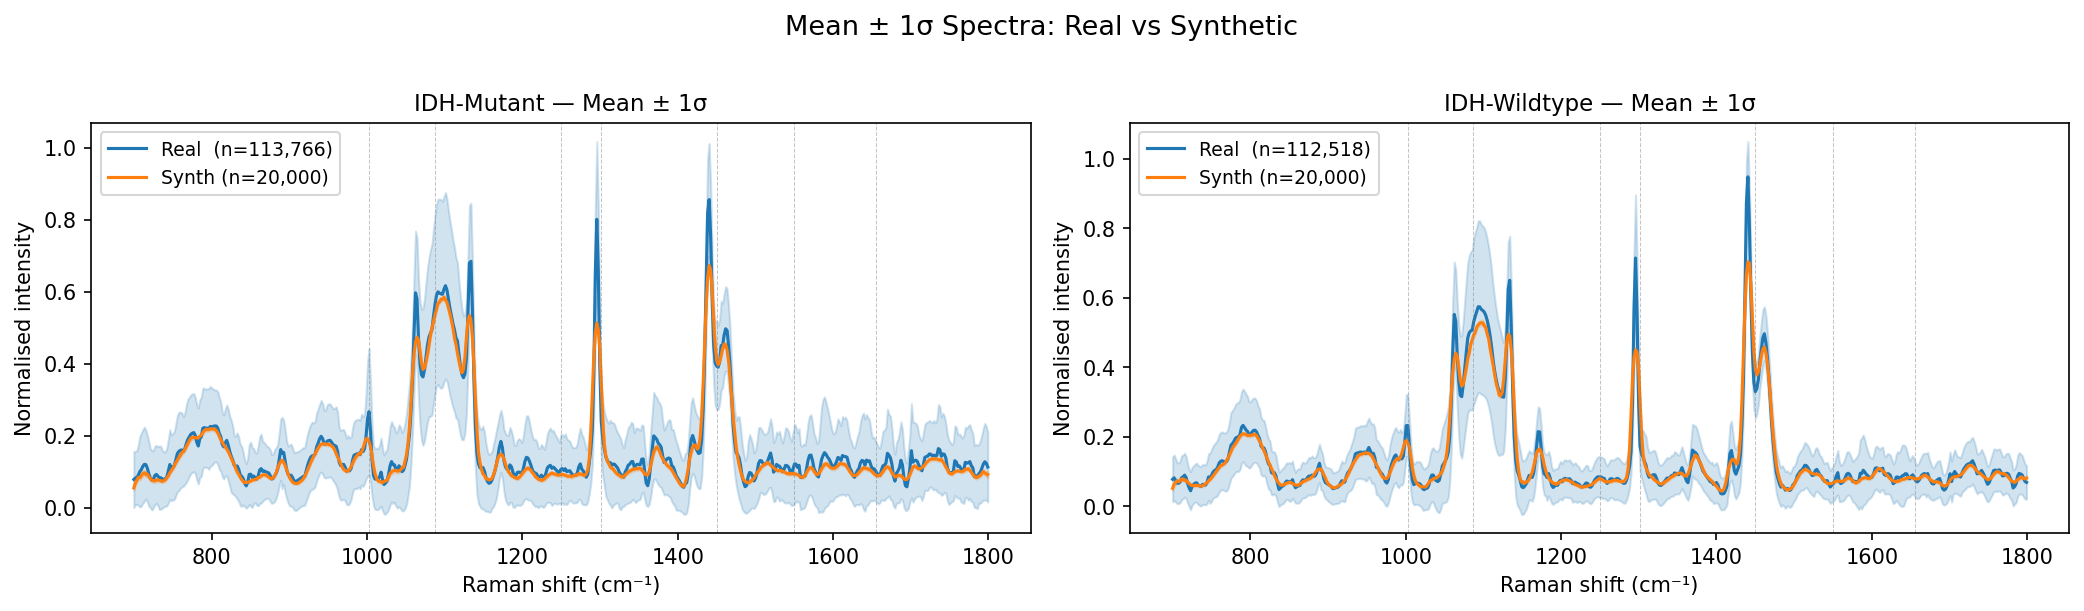


── B_overlay_class0.png ──


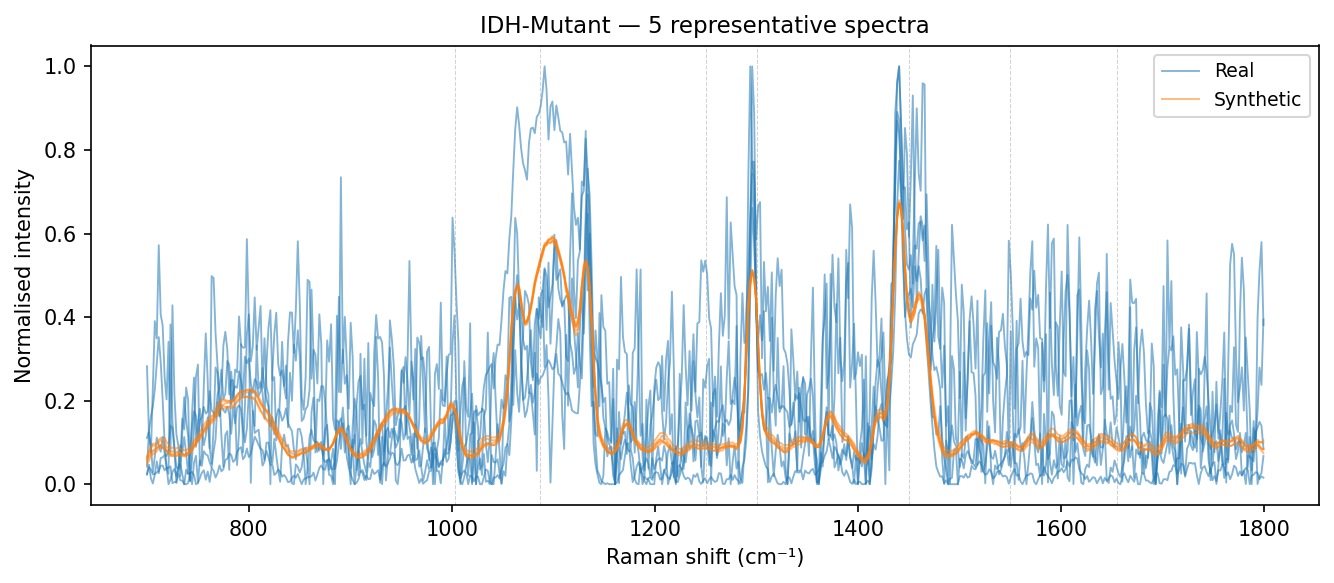


── B_overlay_class1.png ──


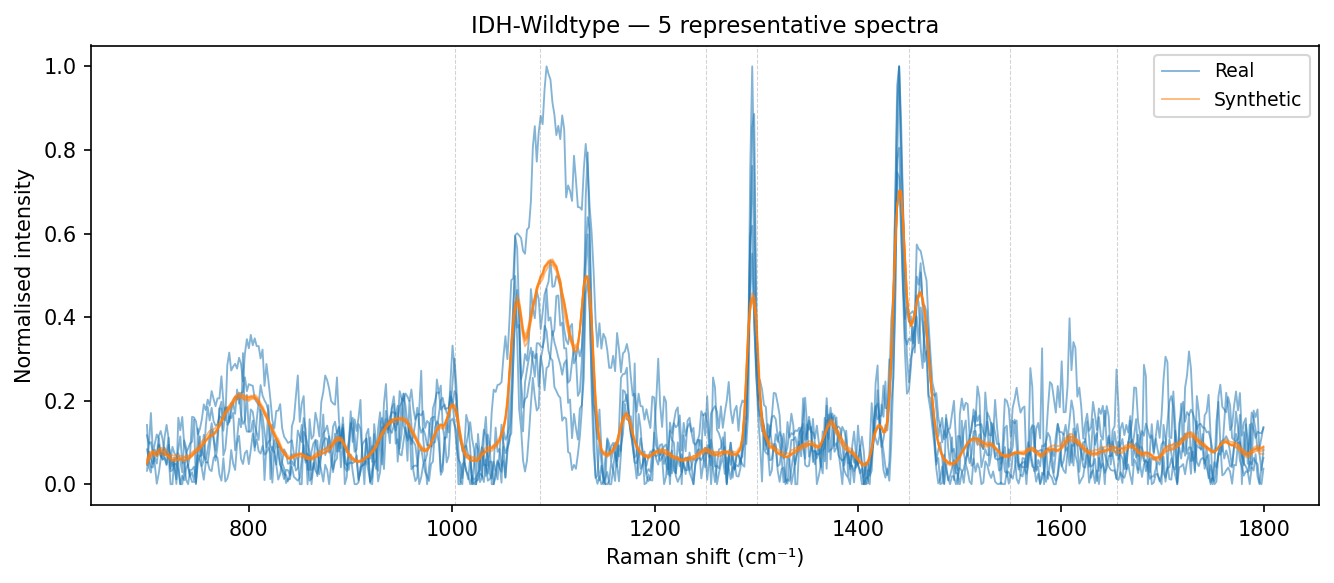


── C_pca.png ──


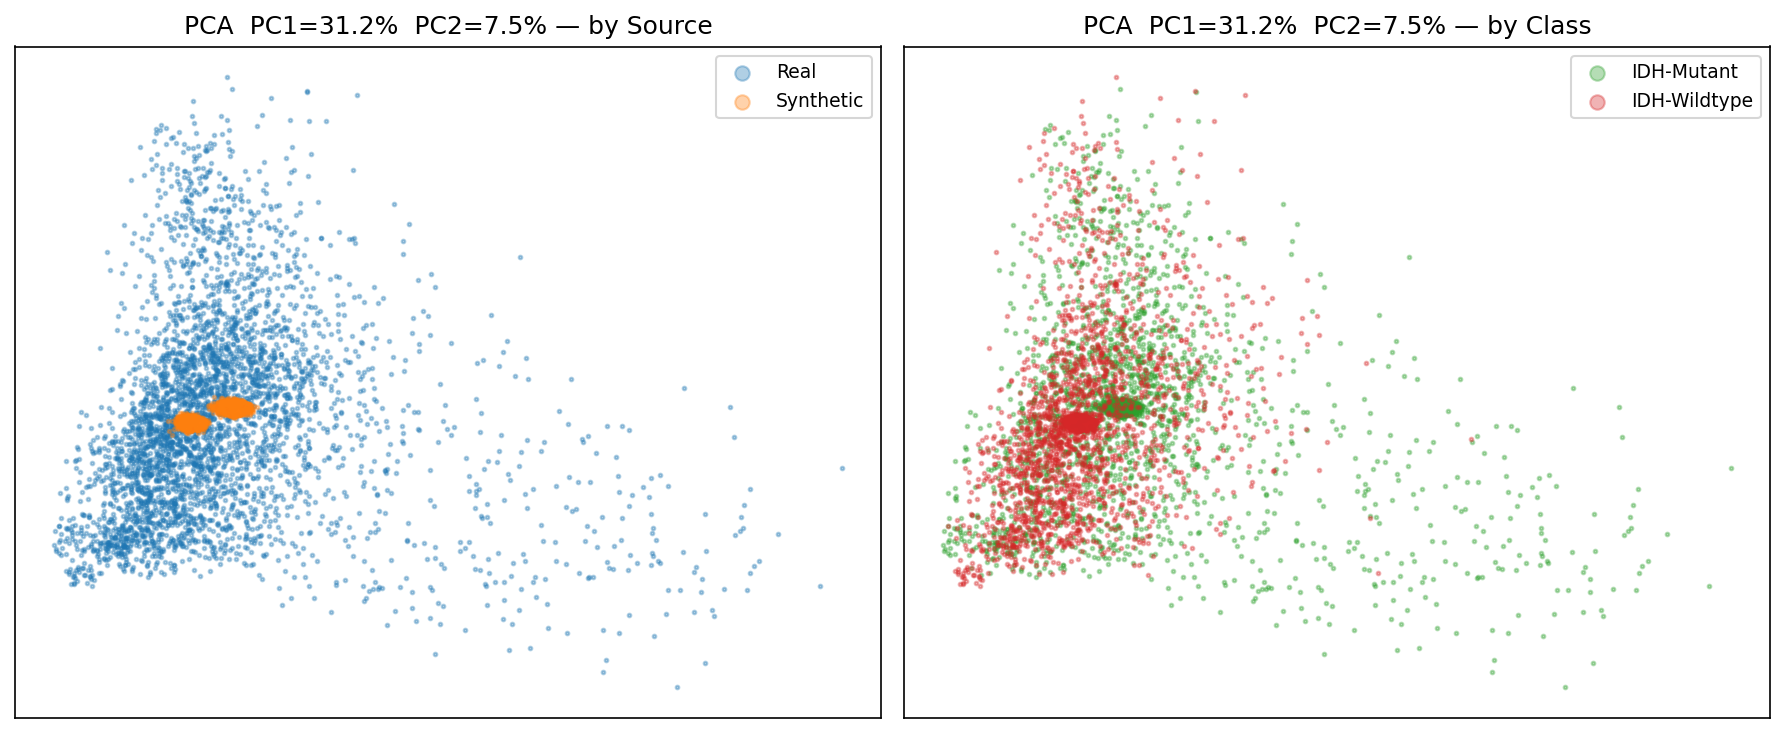


── C_tsne.png ──


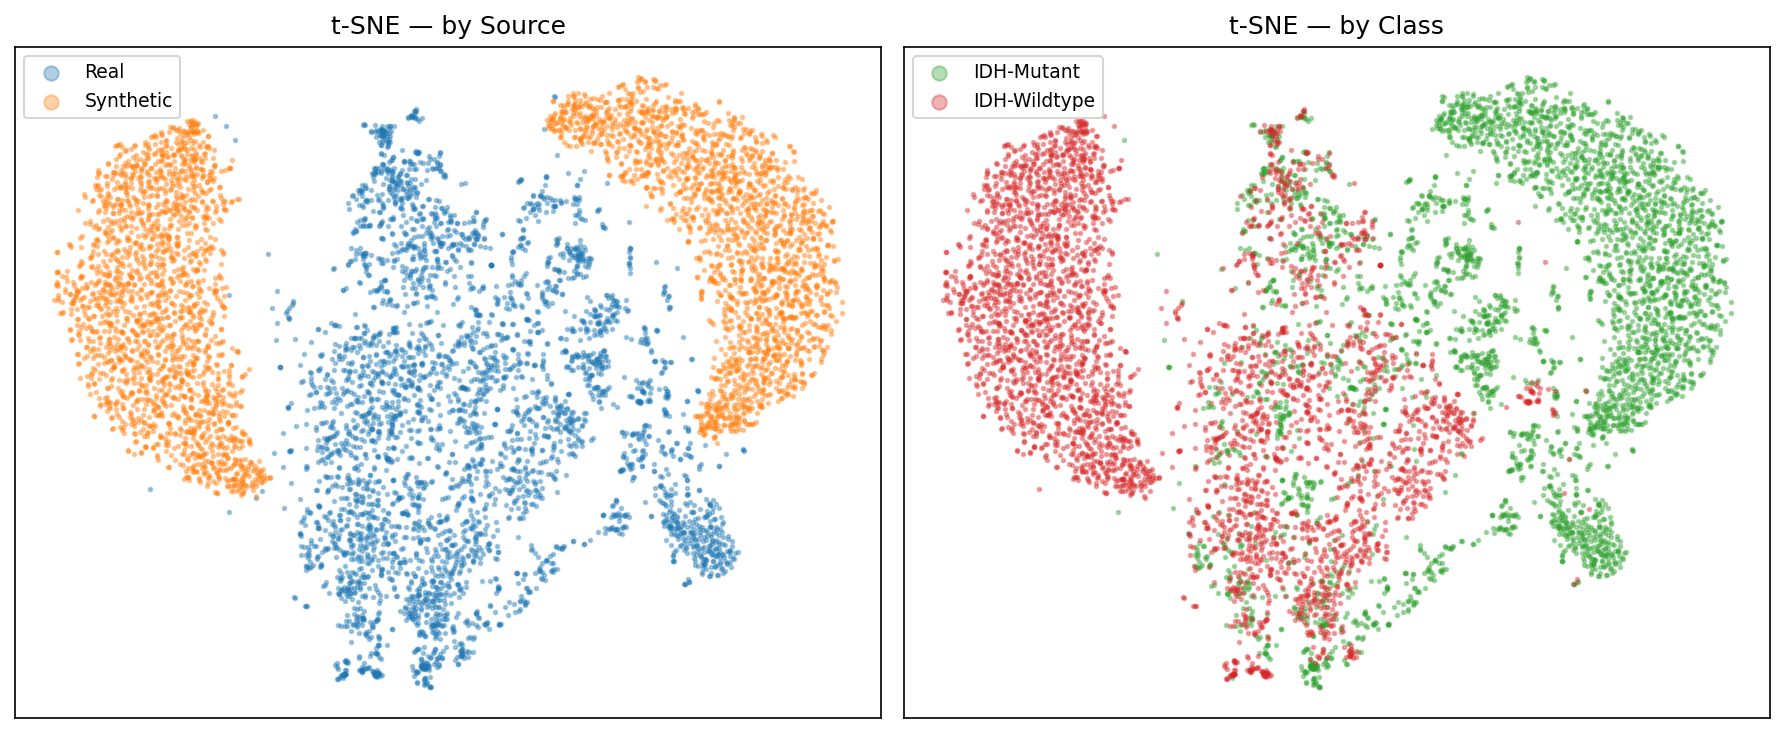


── D_peaks_class0.png ──


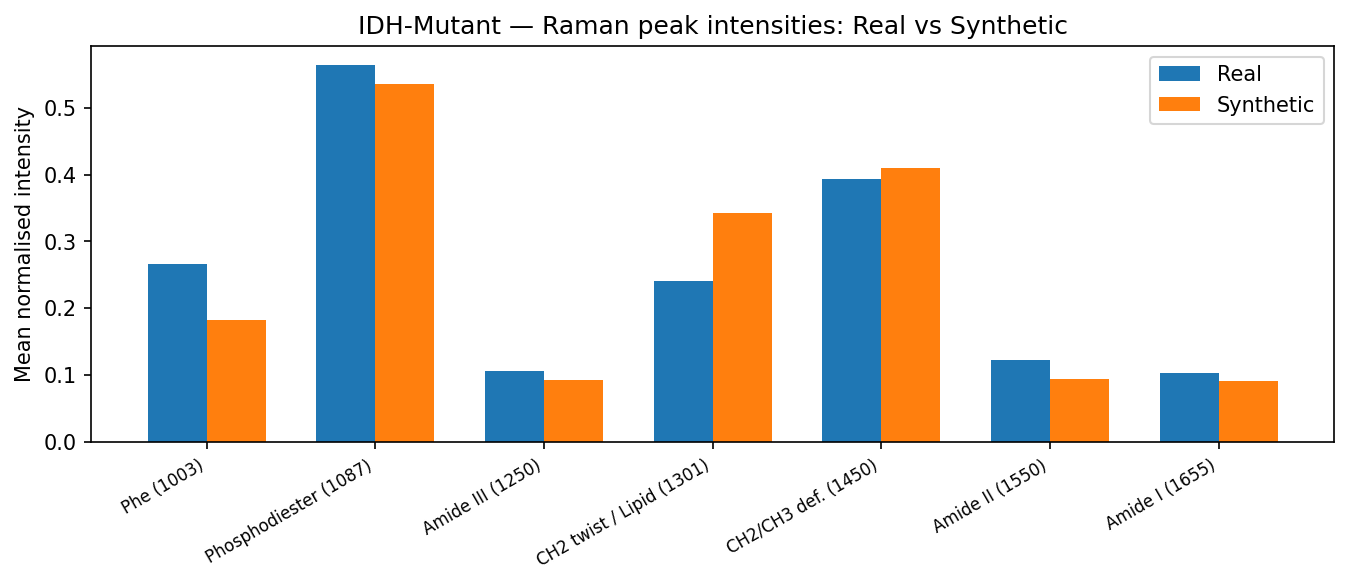


── D_peaks_class1.png ──


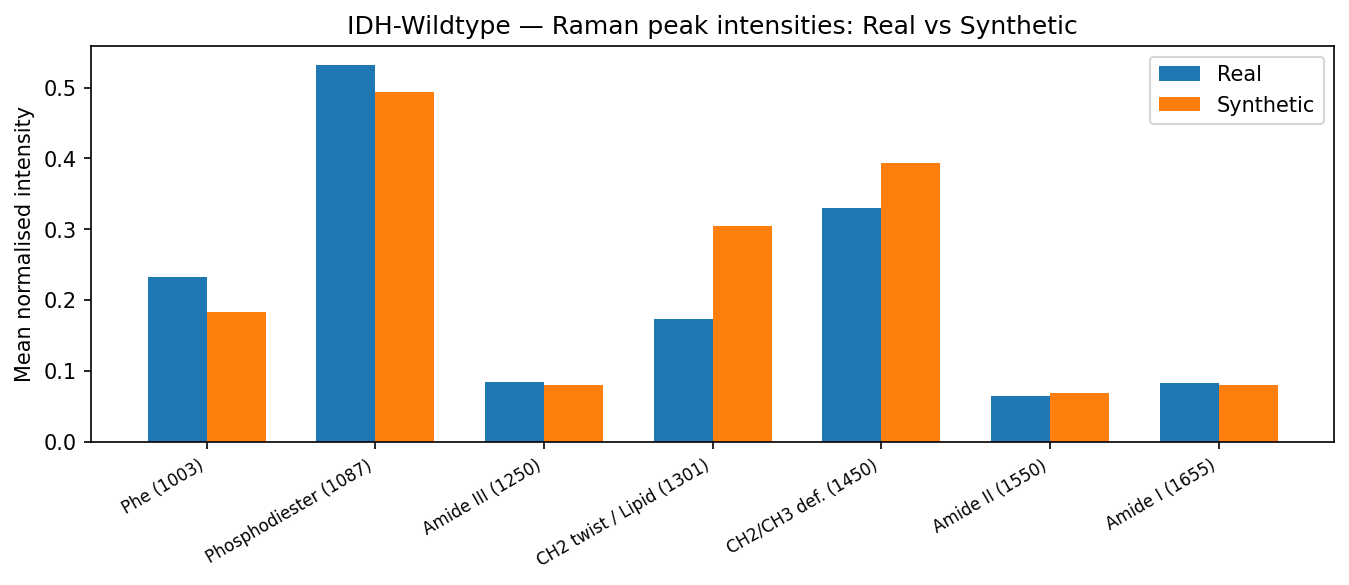


── G_nn_memorisation.png ──


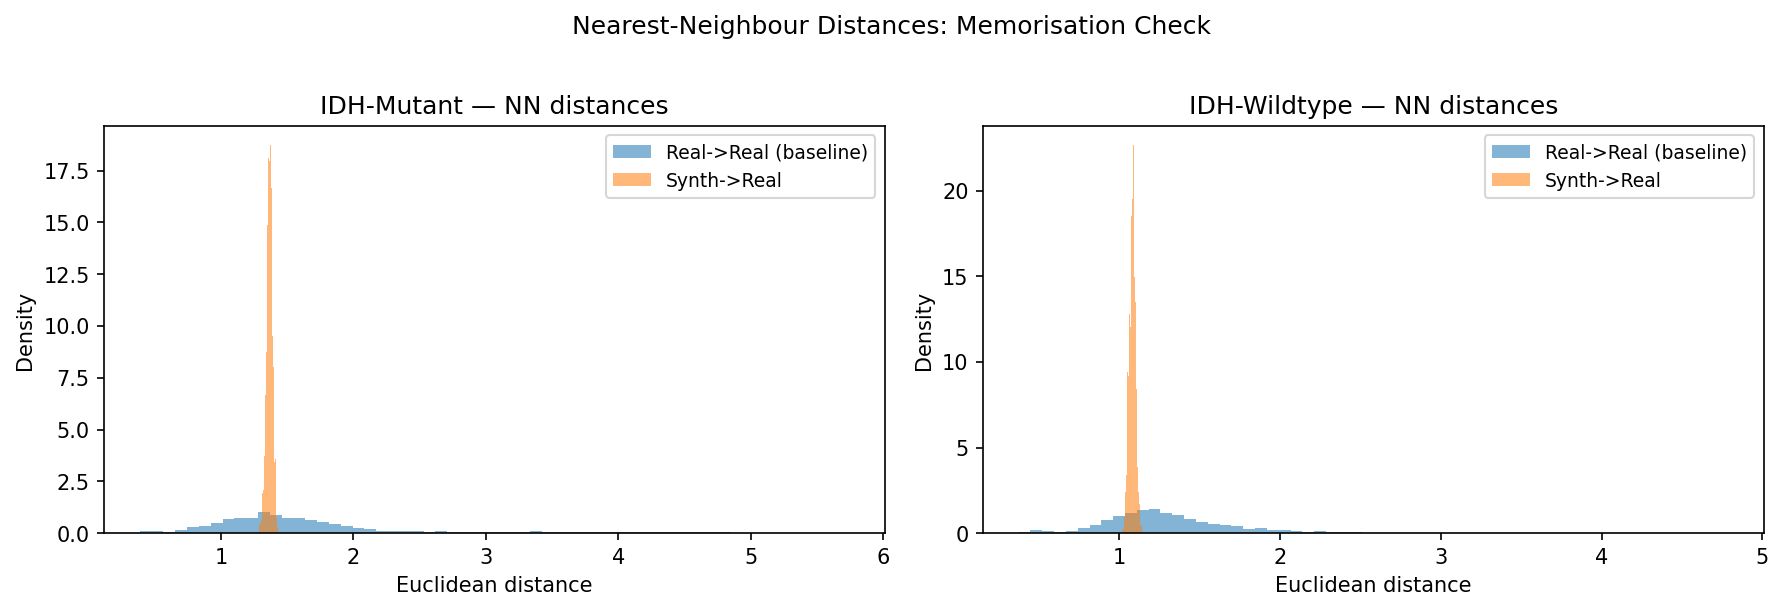


── H_diversity.png ──


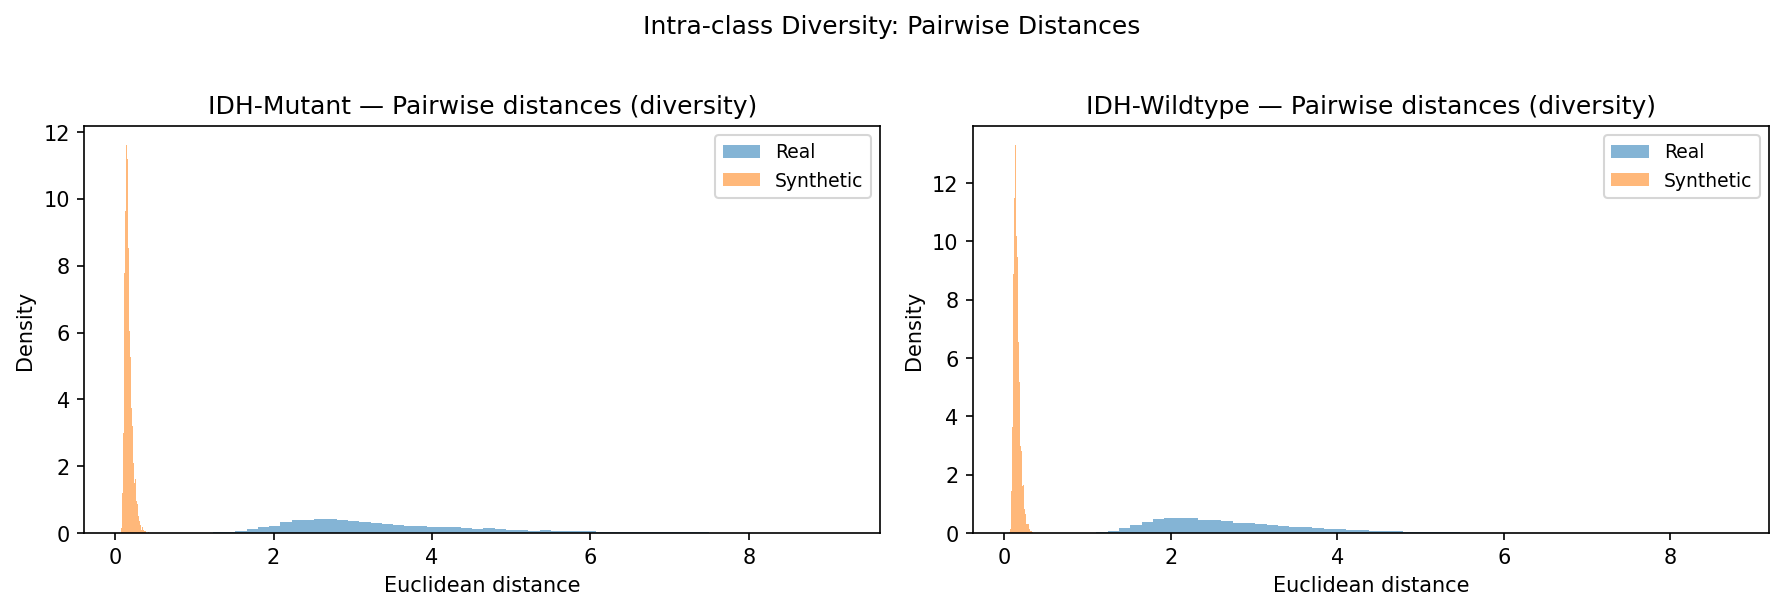

In [6]:
fig_dir = Path(FIGURES_DIR)
pngs    = sorted(fig_dir.glob('*.png'))

if not pngs:
    print('No PNG figures found — did run_all() complete successfully?')
else:
    for png in pngs:
        print(f'\n── {png.name} ──')
        display(Image(str(png), width=900))

## Section 6: Numeric Results Summary

In [7]:
# Pretty-print the scalar metrics (E-H)
for section in ('distributional_distances', 'c2st', 'nn_memorisation', 'diversity'):
    print(f'\n=== {section.upper()} ===')
    for cls_name, metrics in results.get(section, {}).items():
        print(f'  {cls_name}:')
        for k, v in metrics.items():
            print(f'    {k:<35} {v}')


=== DISTRIBUTIONAL_DISTANCES ===
  IDH-Mutant:
    mmd                                 0.355847
    sliced_wasserstein                  0.082274
  IDH-Wildtype:
    mmd                                 0.37604
    sliced_wasserstein                  0.06658

=== C2ST ===
  IDH-Mutant:
    c2st_accuracy                       0.9991
    c2st_auroc                          0.9998
    n_per_source                        5000
  IDH-Wildtype:
    c2st_accuracy                       1.0
    c2st_auroc                          1.0
    n_per_source                        5000

=== NN_MEMORISATION ===
  IDH-Mutant:
    mean_synth_to_real_nn               1.3654
    mean_real_to_real_nn                1.6992
    ratio_sr_rr                         0.8036
    memorisation_flag                   OK
  IDH-Wildtype:
    mean_synth_to_real_nn               1.0818
    mean_real_to_real_nn                1.3132
    ratio_sr_rr                         0.8239
    memorisation_flag                   OK

==

In [8]:
# Flat CSV view
csv_path = Path(METRICS_PATH).with_suffix('.csv')
if csv_path.exists():
    df = pd.read_csv(csv_path)
    display(df)

,section,class,mmd,sliced_wasserstein,c2st_accuracy,c2st_auroc,n_per_source,mean_synth_to_real_nn,mean_real_to_real_nn,ratio_sr_rr,memorisation_flag,real_mean_pairwise,real_std_pairwise,synth_mean_pairwise,synth_std_pairwise,diversity_ratio_synth_real
0,distributional_distances,IDH-Mutant,0.355847,0.082274,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,distributional_distances,IDH-Wildtype,0.376040,0.066580,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,c2st,IDH-Mutant,NaN,NaN,0.9991,0.9998,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,c2st,IDH-Wildtype,NaN,NaN,1.0000,1.0000,5000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,nn_memorisation,IDH-Mutant,NaN,NaN,NaN,NaN,NaN,1.3654,1.6992,0.8036,OK,NaN,NaN,NaN,NaN,NaN
5,nn_memorisation,IDH-Wildtype,NaN,NaN,NaN,NaN,NaN,1.0818,1.3132,0.8239,OK,NaN,NaN,NaN,NaN,NaN
6,diversity,IDH-Mutant,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.4694,1.318,0.1684,0.0464,0.0485
7,diversity,IDH-Wildtype,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.7243,0.936,0.1486,0.0384,0.0546


## Section 7: Raman Peak Table

In [9]:
peak_rows = []
for cls_name, peak_data in results.get('raman_peaks', {}).items():
    for peak_lbl, vals in peak_data.items():
        peak_rows.append({'class': cls_name, 'peak': peak_lbl, **vals})

if peak_rows:
    peak_df = pd.DataFrame(peak_rows)
    display(peak_df.to_string(index=False))

'       class                     peak  wavenumber_cm-1  mean_real  mean_synth  ratio_synth_real\n  IDH-Mutant               Phe (1003)             1003   0.266794    0.183052            0.6861\n  IDH-Mutant    Phosphodiester (1087)             1087   0.564024    0.536081            0.9505\n  IDH-Mutant         Amide III (1250)             1250   0.106335    0.092892            0.8736\n  IDH-Mutant CH2 twist / Lipid (1301)             1301   0.240556    0.342819            1.4251\n  IDH-Mutant      CH2/CH3 def. (1450)             1450   0.393670    0.410003            1.0415\n  IDH-Mutant          Amide II (1550)             1550   0.121780    0.094322            0.7745\n  IDH-Mutant           Amide I (1655)             1655   0.102822    0.091100            0.8860\nIDH-Wildtype               Phe (1003)             1003   0.232554    0.183190            0.7877\nIDH-Wildtype    Phosphodiester (1087)             1087   0.531700    0.493389            0.9279\nIDH-Wildtype         Amide II